# Problema 2 — Regresión en Boston Housing

Dataset clásico de 506 observaciones y 13 atributos del **Boston Housing**. Objetivo: predecir el valor mediano de las viviendas (`medv`).

Fuente: censo de EE.UU. sobre la zona de Boston e información del servicio de censos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

## Análisis exploratorio de datos (EDA)

In [2]:
df = pd.read_csv("/home/santiago/Documentos/ModE/Obligatorio1/problema2/BostonHousing.csv")

print("Dimensiones:", df.shape)
print("Columnas:", list(df.columns))
print("\nTipos de dato:\n", df.dtypes.to_string())
print("\nPrimeras filas:\n", df.head().to_string())
print("\nResumen estadístico:\n", df.describe().T.round(2).to_string())

Dimensiones: (506, 14)
Columnas: ['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'b', 'lstat', 'medv']

Tipos de dato:
 crim       float64
zn         float64
indus      float64
chas         int64
nox        float64
rm         float64
age        float64
dis        float64
rad          int64
tax          int64
ptratio    float64
b          float64
lstat      float64
medv       float64

Primeras filas:
       crim    zn  indus  chas    nox     rm   age     dis  rad  tax  ptratio       b  lstat  medv
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296     15.3  396.90   4.98  24.0
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242     17.8  396.90   9.14  21.6
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242     17.8  392.83   4.03  34.7
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222     18.7  394.63   2.94  33.4
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222   

In [3]:
print("Valores nulos por columna:\n", df.isna().sum().to_string())
print("Filas duplicadas:", df.duplicated().sum())

Valores nulos por columna:
 crim       0
zn         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
b          0
lstat      0
medv       0
Filas duplicadas: 0


In [5]:
target = "medv"
corr = df.corr(numeric_only=True)[target].sort_values().drop(["medv"])
print("Correlación de cada feature con", target + ":")
print(corr.round(3).to_string())

print("Valor medio de medv: ", np.mean(df["medv"]))
print("Desviación estandar de medv: ", np.std(df["medv"]))

Correlación de cada feature con medv:
lstat     -0.738
ptratio   -0.508
indus     -0.484
tax       -0.469
nox       -0.427
crim      -0.388
rad       -0.382
age       -0.377
chas       0.175
dis        0.250
b          0.333
zn         0.360
rm         0.695
Valor medio de medv:  22.532806324110677
Desviación estandar de medv:  9.188011545278203


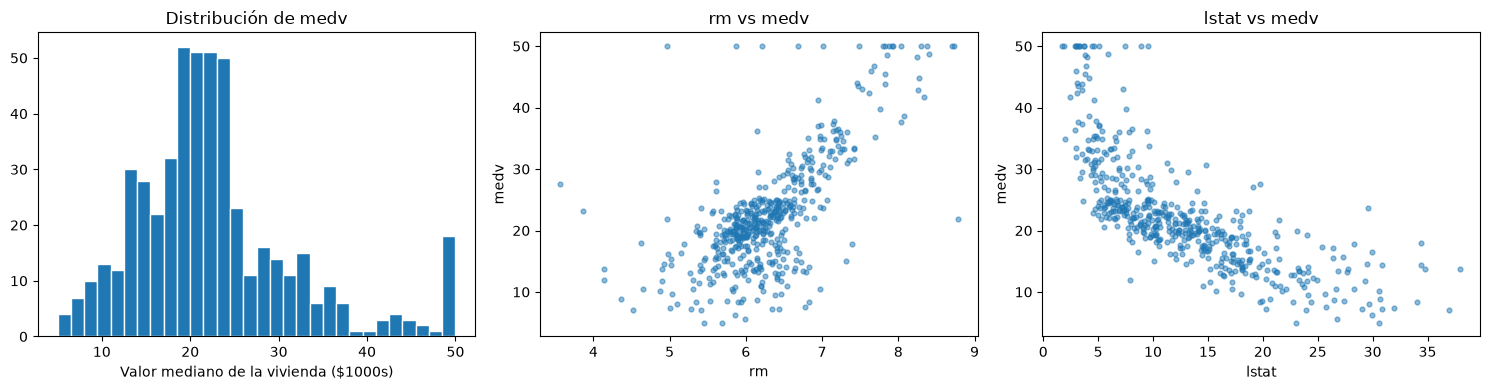

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df[target], bins=30, edgecolor="white")
axes[0].set_title(f"Distribución de {target}")
axes[0].set_xlabel("Valor mediano de la vivienda ($1000s)")

for ax, col in zip(axes[1:], ["rm", "lstat"]):
    ax.scatter(df[col], df[target], alpha=0.5, s=12)
    ax.set_xlabel(col)
    ax.set_ylabel(target)
    ax.set_title(f"{col} vs {target}")

plt.tight_layout()
plt.show()

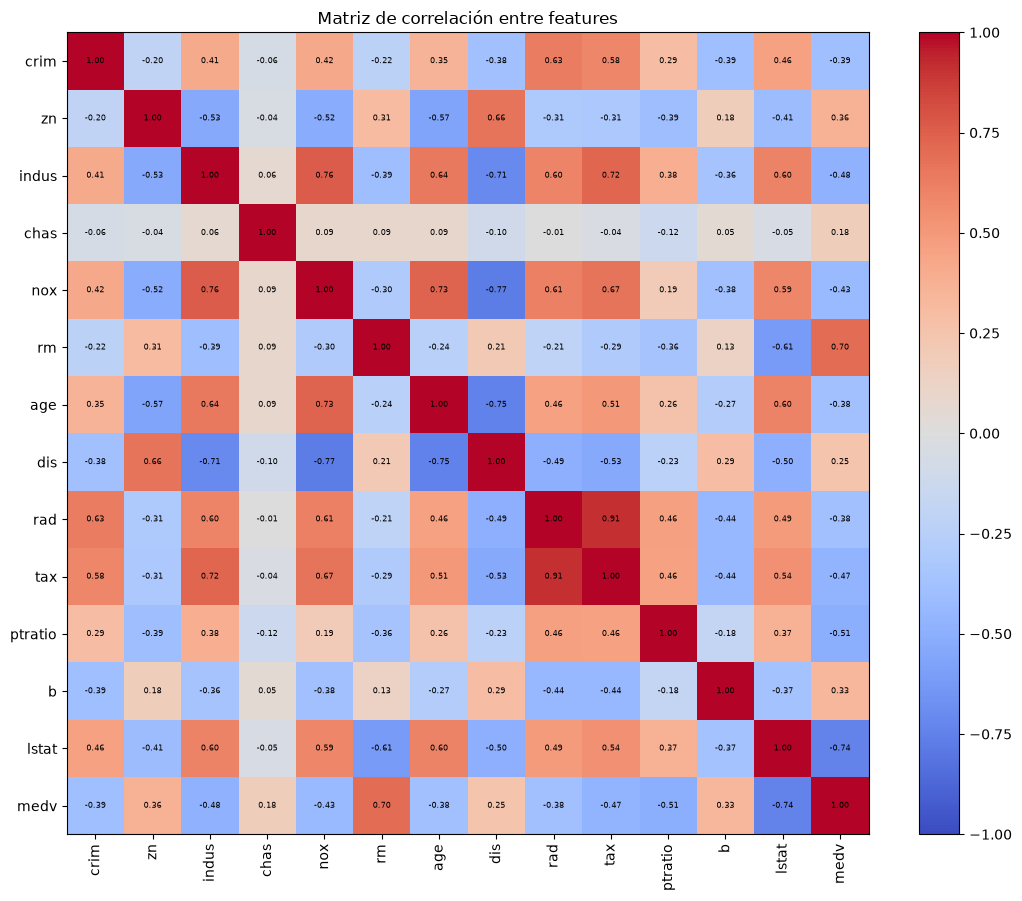

In [6]:
corr_all = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr_all.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_all.columns)), corr_all.columns, rotation=90)
ax.set_yticks(range(len(corr_all.columns)), corr_all.columns)
for i in range(len(corr_all)):
    for j in range(len(corr_all)):
        ax.text(j, i, f"{corr_all.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
ax.set_title("Matriz de correlación entre features")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

**Observaciones del EDA**

- No hay valores nulos ni filas duplicadas; todas las columnas son numéricas.
- medv tiene media ≈ 22.5 y desviación estándar ≈ 9.2.
- Las features con mayor correlación linear con medv: rm (+0.70) y lstat (−0.74).

## Modelado

In [7]:
X = df.drop(columns=[target])
y = df[target]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# grado del polinomio: 1 = lineal, 2 = cuadrático, 3 = cúbico
mse_por_grado = {"grado": [], "train": [], "val": []}
for grado in [1, 2, 3]:
    pl = make_pipeline(PolynomialFeatures(degree=grado, include_bias=False), StandardScaler(), LinearRegression())
    pl.fit(X_train, y_train)
    mse_train = mean_squared_error(y_train, pl.predict(X_train))
    mse_val = mean_squared_error(y_val, pl.predict(X_val))
    mse_por_grado["grado"].append(grado)
    mse_por_grado["train"].append(mse_train)
    mse_por_grado["val"].append(mse_val)
    print(f"polinomio grado {grado}: MSE train={mse_train:.2f}, val = {mse_val:.2f}")

polinomio grado 1: MSE train=21.64, val = 24.29
polinomio grado 2: MSE train=5.13, val = 14.26
polinomio grado 3: MSE train=0.04, val = 4988.47


El bucle entrena regresión lineal con features polinomiales recorriendo el grado: 1 = solo las características originales, 2 = + términos cuadráticos, 3 = + términos cúbicos.

**Sobreajuste:** observar que con grado 3 sin regularizar el MSE train ≈ 0 (el modelo memoriza los datos) pero el MSE val ≈ 4988 (generaliza mal).

In [8]:
# El scaler va después de generar las features polinomiales para que
# Ridge penalice todos los términos (x, x², x³) por igual
grid = make_pipeline(PolynomialFeatures(degree=3, include_bias=False), StandardScaler(), Ridge())
param = {"ridge__alpha": np.logspace(-3, 3, 30)}
gs = GridSearchCV(grid, param, cv=5, scoring="neg_mean_squared_error")
gs.fit(X_train, y_train)
print("Mejor lambda:", gs.best_params_)

# Evaluar el mejor modelo Ridge en train y validación
mejor = gs.best_estimator_
mse_train = mean_squared_error(y_train, mejor.predict(X_train))
mse_val = mean_squared_error(y_val, mejor.predict(X_val))
print(f"Ridge óptimo (grado 3): MSE train={mse_train:.2f}  val={mse_val:.2f}")

Mejor lambda: {'ridge__alpha': np.float64(5.298316906283707)}
Ridge óptimo (grado 3): MSE train=5.21  val=10.32


## Gráficas de evaluación

### 1. MSE en función del grado del polinomio

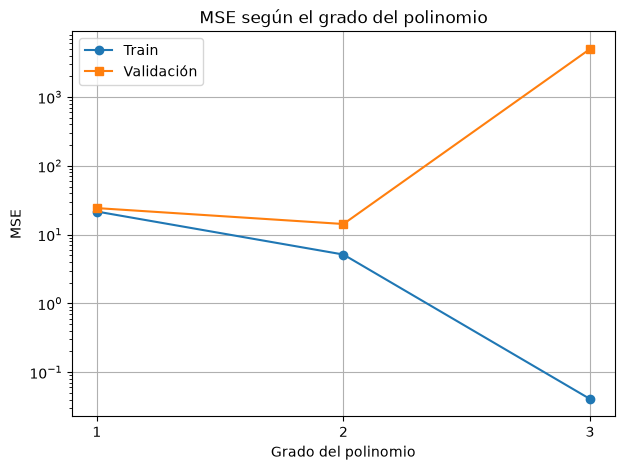

In [9]:
plt.figure(figsize=(7, 5))
plt.plot(mse_por_grado["grado"], mse_por_grado["train"], "o-", label="Train")
plt.plot(mse_por_grado["grado"], mse_por_grado["val"], "s-", label="Validación")
plt.xlabel("Grado del polinomio")
plt.xticks(mse_por_grado["grado"])
plt.ylabel("MSE")
plt.yscale("log")
plt.legend()
plt.title("MSE según el grado del polinomio")
plt.grid(True)
plt.show()

### 2. MSE en función de λ para Ridge (grado 3)

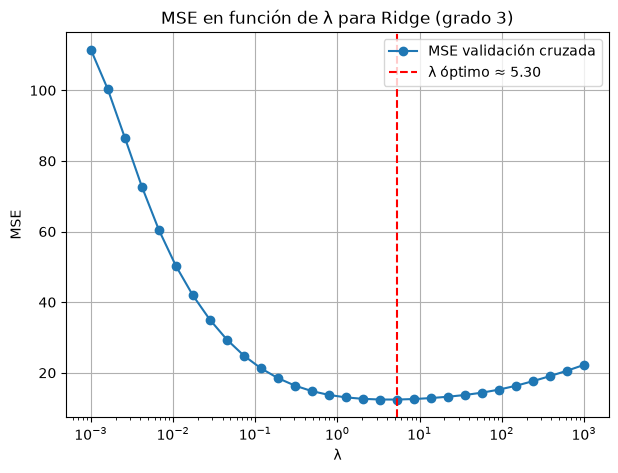

In [10]:
resultados = pd.DataFrame(gs.cv_results_)
lambs = resultados["param_ridge__alpha"].astype(float)
mse_cv = -resultados["mean_test_score"]

plt.figure(figsize=(7, 5))
plt.plot(lambs, mse_cv, "o-", label="MSE validación cruzada")
plt.axvline(gs.best_params_["ridge__alpha"], color="r", ls="--",
            label=f"λ óptimo ≈ {gs.best_params_['ridge__alpha']:.2f}")
plt.xscale("log")
plt.xlabel("λ")
plt.ylabel("MSE")
plt.legend()
plt.title("MSE en función de λ para Ridge (grado 3)")
plt.grid(True)
plt.show()

### 3a. Mejor modelo polinomial: sin regularizar (grado 2) vs con regularización (Ridge grado 3)

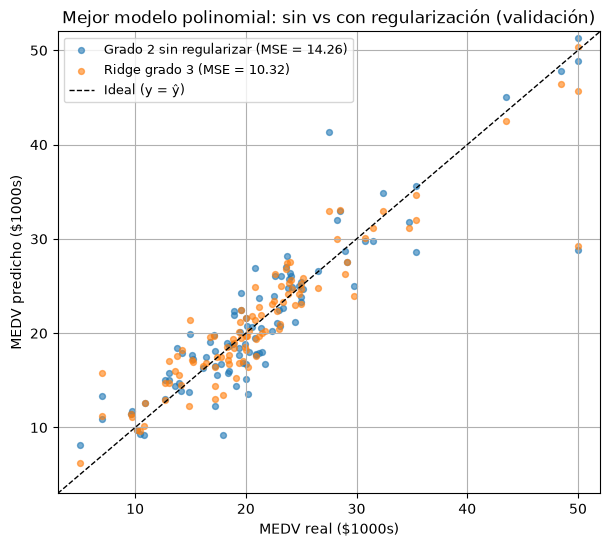

In [11]:
# Mejor modelo SIN regularizar: polinomio grado 2 (por MSE de validación)
pl_g2 = make_pipeline(PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), LinearRegression())
pl_g2.fit(X_train, y_train)
pred_g2 = pl_g2.predict(X_val)

# Mejor modelo CON regularización: Ridge grado 3 (mejor global, λ óptimo por CV)
pred_ridge = mejor.predict(X_val)

mse_g2 = mean_squared_error(y_val, pred_g2)
mse_ridge = mean_squared_error(y_val, pred_ridge)

lim = [y_val.min() - 2, y_val.max() + 2]

plt.figure(figsize=(7, 6))
plt.scatter(y_val, pred_g2, alpha=0.6, s=18, label=f"Grado 2 sin regularizar (MSE = {mse_g2:.2f})")
plt.scatter(y_val, pred_ridge, alpha=0.6, s=18, label=f"Ridge grado 3 (MSE = {mse_ridge:.2f})")
plt.xlim(lim)
plt.ylim(lim)
plt.plot(lim, lim, "k--", lw=1, label="Ideal (y = ŷ)")
plt.xlabel("MEDV real ($1000s)")
plt.ylabel("MEDV predicho ($1000s)")
plt.legend(fontsize=9)
plt.title("Mejor modelo polinomial: sin vs con regularización (validación)")
plt.grid(True)
plt.show()

### 3b. Predicciones vs reales — modelo de grado 3 con y sin regularización

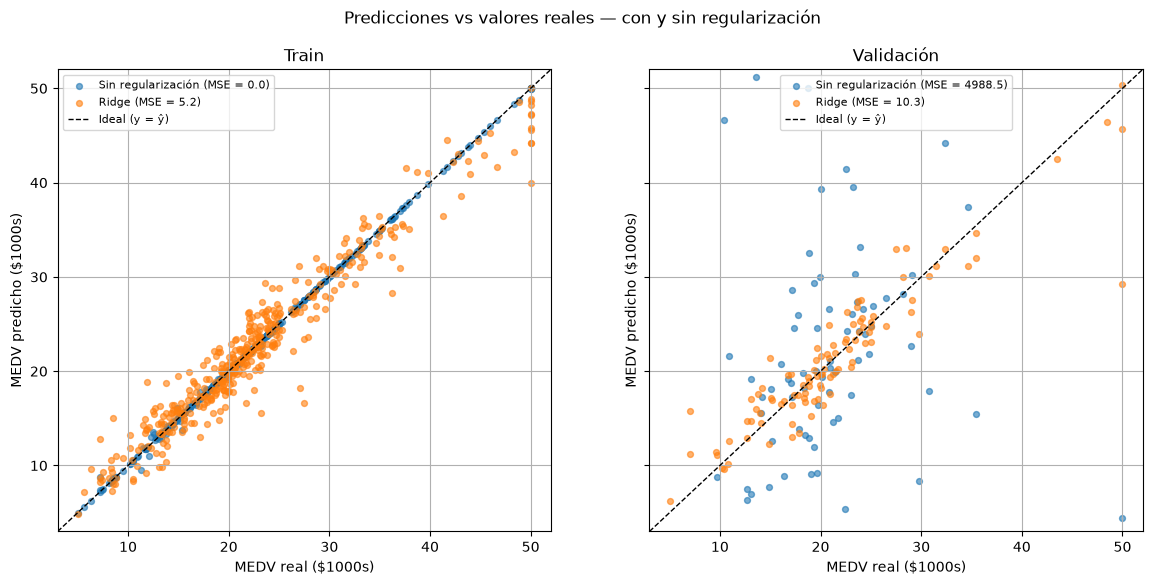

In [12]:
# Modelo de grado 3 SIN regularizar (para comparar con el Ridge óptimo)
pl_sin_reg = make_pipeline(PolynomialFeatures(degree=3, include_bias=False), StandardScaler(), LinearRegression())
pl_sin_reg.fit(X_train, y_train)

# Predicciones en train y validación, con y sin regularización
pred_sin_reg_tr = pl_sin_reg.predict(X_train)
pred_con_reg_tr = mejor.predict(X_train)
pred_sin_reg_va = pl_sin_reg.predict(X_val)
pred_con_reg_va = mejor.predict(X_val)

# rango común para ambos paneles
lim = [min(y_train.min(), y_val.min()) - 2, max(y_train.max(), y_val.max()) + 2]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

for ax, (xs, psr, pcr, titulo) in zip(
    axes,
    [(y_train, pred_sin_reg_tr, pred_con_reg_tr, "Train"),
     (y_val, pred_sin_reg_va, pred_con_reg_va, "Validación")],
):
    ax.scatter(xs, psr, alpha=0.6, s=18,
               label=f"Sin regularización (MSE = {mean_squared_error(xs, psr):.1f})")
    ax.scatter(xs, pcr, alpha=0.6, s=18,
               label=f"Ridge (MSE = {mean_squared_error(xs, pcr):.1f})")
    ax.plot(lim, lim, "k--", lw=1, label="Ideal (y = ŷ)")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_xlabel("MEDV real ($1000s)")
    ax.set_ylabel("MEDV predicho ($1000s)")
    ax.set_title(titulo)
    ax.grid(True)
    ax.legend(fontsize=8)

fig.suptitle("Predicciones vs valores reales — con y sin regularización")
plt.show()